In [37]:
%pip install gdown
%pip install xgboost

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from wordcloud import WordCloud
import gdown
from gensim.models import KeyedVectors
from sklearn.tree import DecisionTreeRegressor
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc,mean_squared_error, r2_score,accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from tensorflow.keras.optimizers import Adam
from xgboost import XGBRegressor
from sklearn.svm import SVR
import util_bagging as ubagging
df = pd.read_csv('news1.csv')

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
df.head()

,Unnamed: 0.1,Unnamed: 0,title,text,label
0,0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


In [3]:
print(df['label'].value_counts())

label
FAKE                                                                                                                                      3186
REAL                                                                                                                                      3154
 we have now learned that they don’t even share the same religion.                                                                           2
 usually sex-related. It also involves at least minor sacrifices: one “recipe” calls for cutting one’s figure and “eat[ing] the pain.”       2
Name: count, dtype: int64


In [4]:
print(df['label'].unique())

['FAKE' 'REAL' nan
 ' we have now learned that they don’t even share the same religion.'
 ' usually sex-related. It also involves at least minor sacrifices: one “recipe” calls for cutting one’s figure and “eat[ing] the pain.”']


In [5]:
df = df[df['label'].isin(['FAKE', 'REAL'])] 

In [6]:
print(df['label'].value_counts())

label
FAKE    3186
REAL    3154
Name: count, dtype: int64


### Separamos en entrenamiento y test ###

In [7]:
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.33, random_state=42)


### Convertimos las cadenas a string ### 

In [8]:
X_train = X_train.astype(str)
X_test = X_test.astype(str)

### Juntamos X e Y , eliminamos los valores nulos y los volvemos a separar ### 

In [9]:
train_df = pd.DataFrame({'X': X_train, 'y': y_train})

# Eliminar filas donde y sea NaN
train_df = train_df.dropna(subset=['y'])

# Separar nuevamente
X_train = train_df['X']
y_train = train_df['y']

### Mostramos las palabras mas repetidas ###

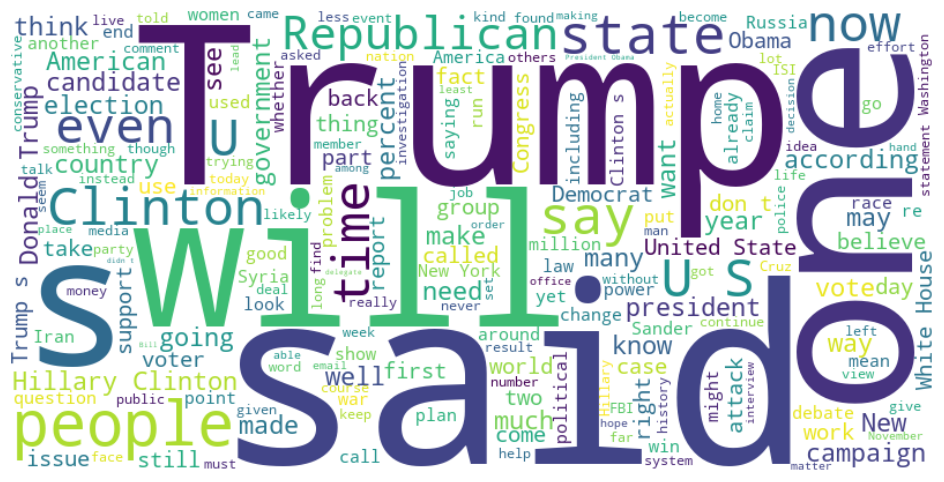

In [10]:
textos = ' '.join(df['text'].astype(str))  # aseguramos que todo sea str

# Generar la nube de palabras
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(textos)

# Mostrar la imagen generada
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

### Descargamos un modelo ya entrenado ### 

In [11]:
url = 'https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK'
output = 'GoogleNews-vectors-negative300.bin'
gdown.download(url, output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK
From (redirected): https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK&confirm=t&uuid=78a1c56f-a3b6-4835-a9e1-8f320a8951ab
To: c:\Users\gabby\Documents\Data Science\Machine learning\Redes neuronales\TPFinal\GoogleNews-vectors-negative300.bin
100%|██████████| 3.64G/3.64G [04:27<00:00, 13.6MB/s]


'GoogleNews-vectors-negative300.bin'

In [12]:
y_train = y_train.map({'FAKE': 0, 'REAL': 1})
y_test = y_test.map({'FAKE': 0, 'REAL': 1})

In [14]:
word2vec = KeyedVectors.load_word2vec_format(output, binary=True)
tokenizer = Tokenizer(num_words=80000)
tokenizer.fit_on_texts(X_train)

sequences_train = tokenizer.texts_to_sequences(X_train)
sequences_test = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(sequences_train, maxlen=80)
X_test_pad = pad_sequences(sequences_test, maxlen=80)

word_index = tokenizer.word_index
embedding_dim = 300
embedding_matrix = np.zeros((80000, embedding_dim))
for word, i in word_index.items():
    if i < 80000:
        try:
            embedding_vector = word2vec[word]
            embedding_matrix[i] = embedding_vector
        except KeyError:
            continue

In [15]:
embedding_dim = 300
max_len = 80
num_words = 80000


tokenizer = Tokenizer(num_words=num_words)
tokenizer.fit_on_texts(X_train)

sequences_train = tokenizer.texts_to_sequences(X_train)
sequences_test = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(sequences_train, maxlen=max_len)
X_test_pad = pad_sequences(sequences_test, maxlen=max_len)

# Crear la matriz de embeddings
word_index = tokenizer.word_index
embedding_matrix = np.zeros((num_words, embedding_dim))
for word, i in word_index.items():
    if i < num_words:
        try:
            embedding_vector = word2vec[word]
            embedding_matrix[i] = embedding_vector
        except KeyError:
            continue

# Modelo
model = Sequential()
model.add(Embedding(input_dim=num_words,
                    output_dim=embedding_dim,
                    weights=[embedding_matrix],
                    input_length=max_len,
                    trainable=False))  # No entrenamos los embeddings
model.add(LSTM(128, return_sequences=False))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))  # Clasificación binaria

# Compilar
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])


history = model.fit(
    X_train_pad,
    np.array(y_train).astype("float32"),
    batch_size=64,
    epochs=20,              # Entrena siempre 20 épocas
    validation_data=(X_test_pad, np.array(y_test).astype("float32")),
    verbose=1               # Muestra el progreso por época
)


Epoch 1/20
67/67 [==============================] - 4s 17ms/step - loss: 0.5812 - accuracy: 0.7066 - val_loss: 0.4900 - val_accuracy: 0.7750
Epoch 2/20
67/67 [==============================] - 1s 13ms/step - loss: 0.4462 - accuracy: 0.7966 - val_loss: 0.3960 - val_accuracy: 0.8290
Epoch 3/20
67/67 [==============================] - 1s 13ms/step - loss: 0.3717 - accuracy: 0.8439 - val_loss: 0.3700 - val_accuracy: 0.8438
Epoch 4/20
67/67 [==============================] - 1s 13ms/step - loss: 0.3432 - accuracy: 0.8580 - val_loss: 0.3854 - val_accuracy: 0.8285
Epoch 5/20
67/67 [==============================] - 1s 13ms/step - loss: 0.2995 - accuracy: 0.8726 - val_loss: 0.3559 - val_accuracy: 0.8481
Epoch 6/20
67/67 [==============================] - 1s 12ms/step - loss: 0.2653 - accuracy: 0.8926 - val_loss: 0.2911 - val_accuracy: 0.8753
Epoch 7/20
67/67 [==============================] - 1s 13ms/step - loss: 0.2299 - accuracy: 0.9105 - val_loss: 0.4044 - val_accuracy: 0.8146
Epoch 8/20
67

In [16]:
y_test = np.array(y_test).astype("float32")

# Ahora sí podés evaluar el modelo
loss, accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Loss: {loss:.4f}")

Accuracy: 0.9173
Loss: 0.3298


66/66 [==============================] - 1s 7ms/step
              precision    recall  f1-score   support

         0.0       0.92      0.92      0.92      1083
         1.0       0.91      0.92      0.91      1010

    accuracy                           0.92      2093
   macro avg       0.92      0.92      0.92      2093
weighted avg       0.92      0.92      0.92      2093



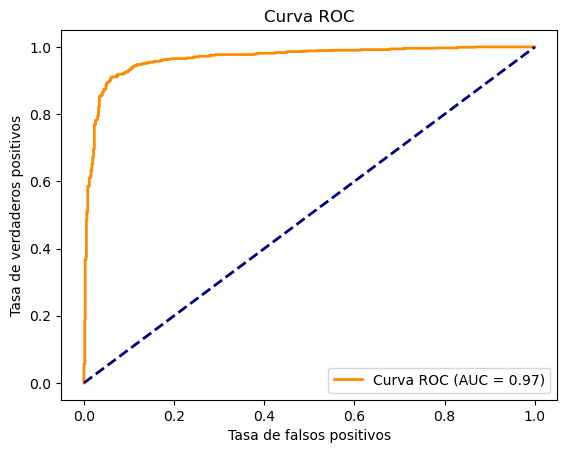

In [17]:
y_pred_proba = model.predict(X_test_pad)

# Convertir probabilidades a clase (si querés el reporte)
y_pred = (y_pred_proba > 0.5).astype("int32")

# Reporte de clasificación
print(classification_report(y_test, y_pred))

# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

In [18]:
df_pred = pd.read_csv('news_pred.csv')
pred_sequences = tokenizer.texts_to_sequences(df_pred['text'])
pred_pad = pad_sequences(pred_sequences, maxlen=80)
pred_probs = model.predict(pred_pad)
pred_labels = (pred_probs > 0.5).astype(int)

df_pred['prediction'] = pred_labels
print(df_pred)

1/1 [==============================] - 0s 19ms/step
                                               title  \
0  At least 12 dead after terror attack at Paris ...   
1  World leaders' personal chefs sample Indian ma...   
2  An Open Letter to Black South African Police O...   
3  Gay man finds it in himself to tolerate religi...   
4  US Spy Chief: Asking North Korea To Stop Nuke ...   
5  The Devastating Consequences Of A 'Small' Rise...   
6  Cost, logistics of Obama immigration plan rais...   

                                                text label  prediction  
0  Gunmen stormed the offices of the satirical ne...  REAL           1  
1  World leaders' personal chefs sample Indian ma...  FAKE           0  
2  Tweet Widget by Black Power Front \nWith stude...  FAKE           0  
3  Gay man finds it in himself to tolerate religi...  FAKE           0  
4  Get short URL 0 27 0 0 On Tuesday, National In...  FAKE           0  
5  More Floods, More Drought Inevitable. How Bad ...  REAL   

In [2]:
df2 = pd.read_csv('OnlineNewsPopularity.csv')

df2.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [3]:
# 2. Quitar espacios en blanco de los nombres de las columnas
df2.columns = df2.columns.str.strip()

# 3. Explorar columnas para decidir cuáles eliminar
print(df2.columns)

Index(['url', 'timedelta', 'n_tokens_title', 'n_tokens_content',
       'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens',
       'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos',
       'average_token_length', 'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentiment_polarity', 'global_rate_positive_words',
     

In [4]:
df2 = df2.drop(columns=['url', 'timedelta'])


In [5]:
def data_quality_analysis(df2):
 
    result_df = pd.DataFrame(columns=['Columna', 'Tipo de dato', 'Valores únicos', 'Valores faltantes'])

    columns = df2.columns
    data_types = df2.dtypes.to_list()
    unique_values = [df2[column].nunique() for column in columns]
    missing_values = [df2[column].isnull().sum() for column in columns]

   
    result_df['Columna'] = columns
    result_df['Tipo de dato'] = data_types
    result_df['Valores únicos'] = unique_values
    result_df['Valores faltantes'] = missing_values

    return result_df

In [6]:
analysis_result = data_quality_analysis(df2).set_index('Columna')
print(analysis_result.sort_values('Tipo de dato'))

                              Tipo de dato  Valores únicos  Valores faltantes
Columna                                                                      
shares                               int64            1454                  0
weekday_is_wednesday               float64               2                  0
weekday_is_thursday                float64               2                  0
weekday_is_friday                  float64               2                  0
weekday_is_saturday                float64               2                  0
weekday_is_sunday                  float64               2                  0
is_weekend                         float64               2                  0
LDA_00                             float64           39337                  0
LDA_01                             float64           39098                  0
LDA_02                             float64           39525                  0
LDA_03                             float64           38963      

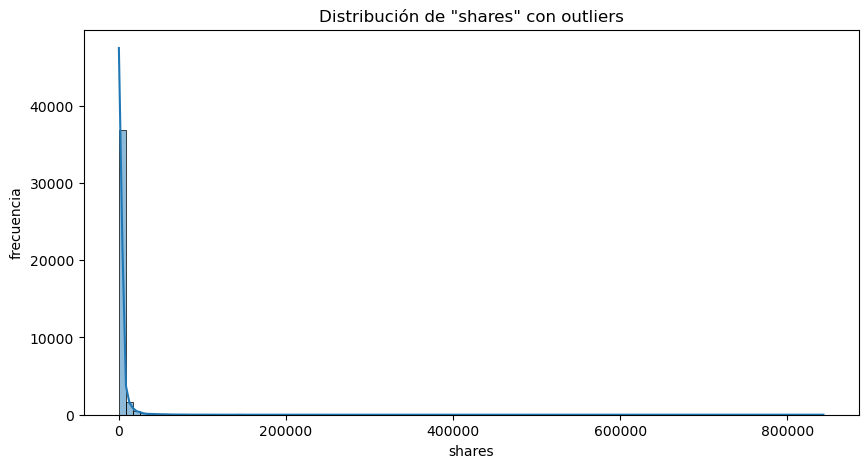

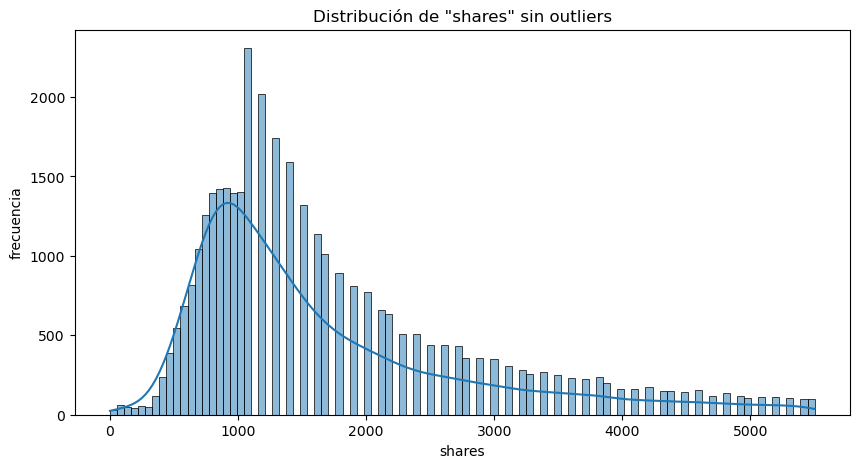

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(df2['shares'], bins=100, kde=True)
plt.title('Distribución de "shares" con outliers')
plt.xlabel('shares')
plt.ylabel('frecuencia')
plt.show()

# Eliminar outliers usando IQR
Q1 = df2['shares'].quantile(0.25)
Q3 = df2['shares'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df2_sin_outliers = df2[(df2['shares'] >= limite_inferior) & (df2['shares'] <= limite_superior)]

# Histograma sin outliers
plt.figure(figsize=(10, 5))
sns.histplot(df2_sin_outliers['shares'], bins=100, kde=True)
plt.title('Distribución de "shares" sin outliers')
plt.xlabel('shares')
plt.ylabel('frecuencia')
plt.show()

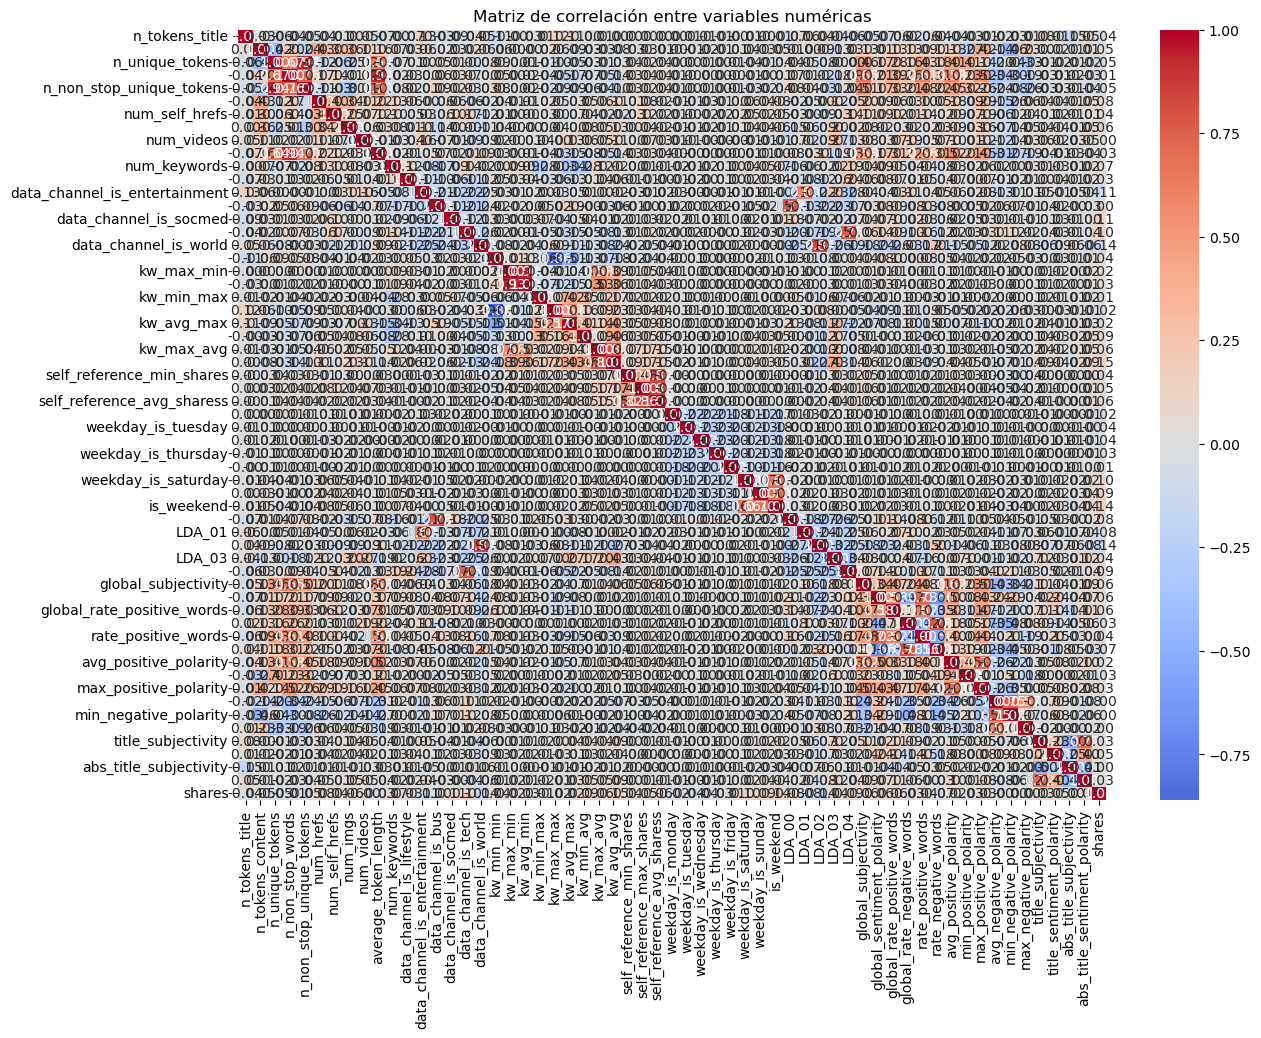

In [8]:
# Seleccionar variables numéricas
numericas = df2_sin_outliers.select_dtypes(include=['int64', 'float64'])

# Calcular matriz de correlación
corr = numericas.corr()

# Mostrar heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title('Matriz de correlación entre variables numéricas')
plt.show()

In [9]:
umbral = 0.7
correlaciones_altas = []

for i in corr.columns:
    for j in corr.columns:
        if i != j and abs(corr.loc[i, j]) > umbral:
            par = tuple(sorted((i, j)))
            if par not in correlaciones_altas:
                correlaciones_altas.append(par)

# Mostrar los pares y sus valores de correlación
print("Pares de variables con correlación > 0.7 (en valor absoluto):")
for i, j in correlaciones_altas:
    print(f"{i} - {j}: {corr.loc[i, j]:.2f}")

Pares de variables con correlación > 0.7 (en valor absoluto):
n_non_stop_unique_tokens - n_unique_tokens: 0.94
n_non_stop_unique_tokens - n_non_stop_words: 0.76
average_token_length - n_non_stop_words: 0.94
LDA_00 - data_channel_is_bus: 0.78
LDA_04 - data_channel_is_tech: 0.75
LDA_02 - data_channel_is_world: 0.84
kw_max_max - kw_min_min: -0.86
kw_avg_min - kw_max_min: 0.93
kw_avg_avg - kw_max_avg: 0.80
self_reference_avg_sharess - self_reference_min_shares: 0.82
self_reference_avg_sharess - self_reference_max_shares: 0.86
is_weekend - weekday_is_sunday: 0.70
global_sentiment_polarity - rate_positive_words: 0.73
global_rate_negative_words - rate_negative_words: 0.78
avg_negative_polarity - min_negative_polarity: 0.75
abs_title_sentiment_polarity - title_subjectivity: 0.72


In [10]:
numericas_filtradas = numericas.copy()

# Crear un set para guardar variables ya eliminadas
eliminadas = set()

# Recorrer pares y eliminar una variable de cada par
for i in corr.columns:
    for j in corr.columns:
        if i != j and abs(corr.loc[i, j]) > 0.7:
            if j not in eliminadas and i not in eliminadas:
                eliminadas.add(j)  # Podrías elegir eliminar 'i' también

# Eliminar columnas del DataFrame
df2_reducido = numericas_filtradas.drop(columns=eliminadas)

# Mostrar variables eliminadas
print("Variables eliminadas por alta correlación (> 0.7):")
print(sorted(eliminadas))

Variables eliminadas por alta correlación (> 0.7):
['LDA_00', 'LDA_02', 'LDA_04', 'abs_title_sentiment_polarity', 'average_token_length', 'is_weekend', 'kw_avg_avg', 'kw_avg_min', 'kw_max_max', 'min_negative_polarity', 'n_non_stop_unique_tokens', 'rate_negative_words', 'rate_positive_words', 'self_reference_avg_sharess']


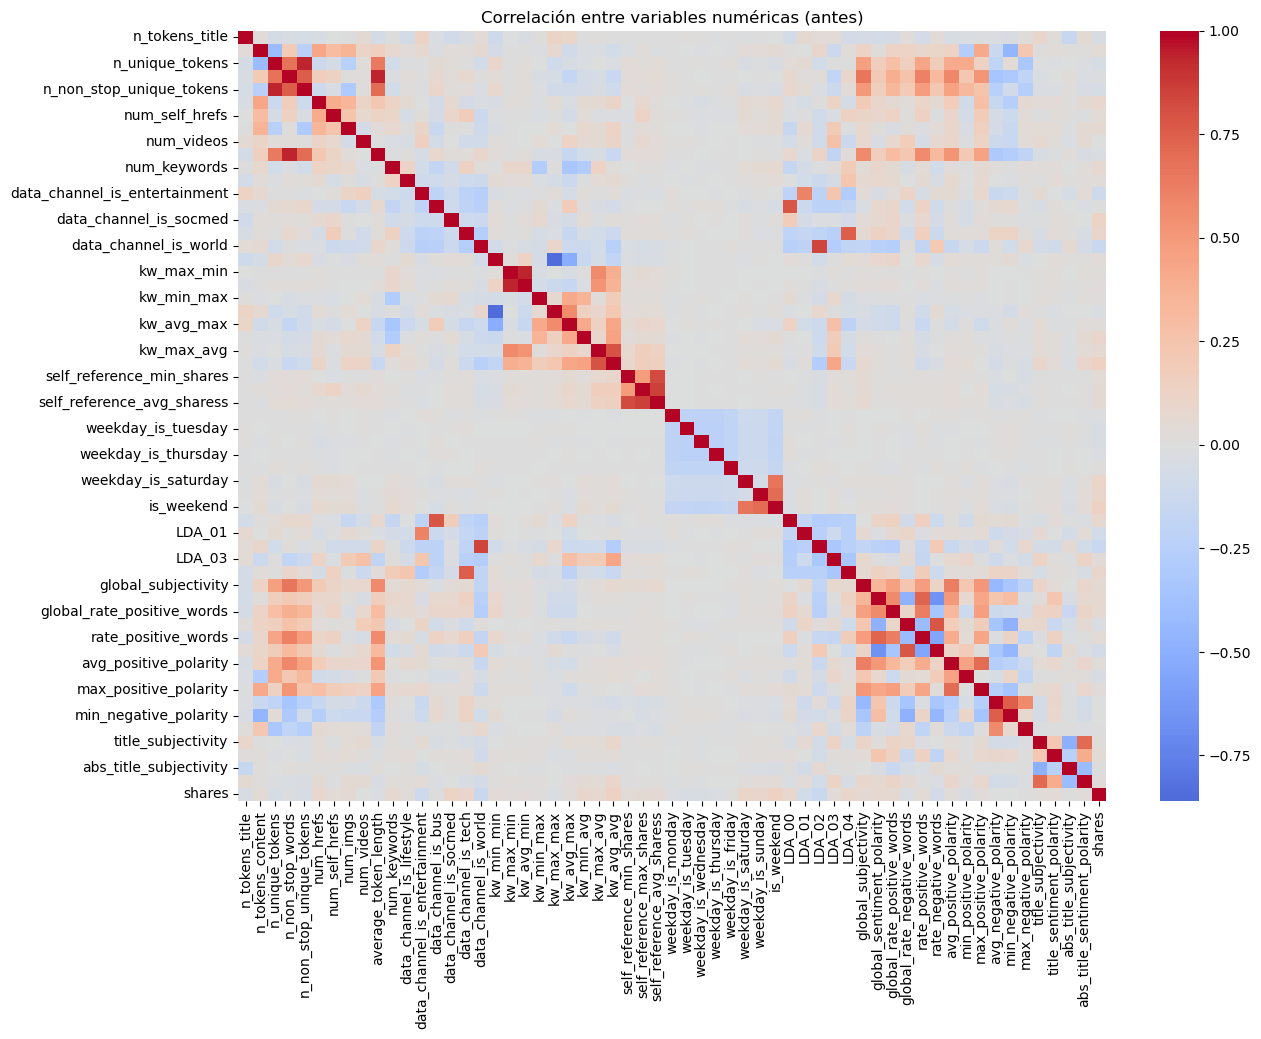

In [11]:
plt.figure(figsize=(14, 10))
sns.heatmap(numericas.corr(), annot=False, cmap='coolwarm', center=0)
plt.title('Correlación entre variables numéricas (antes)')
plt.show()


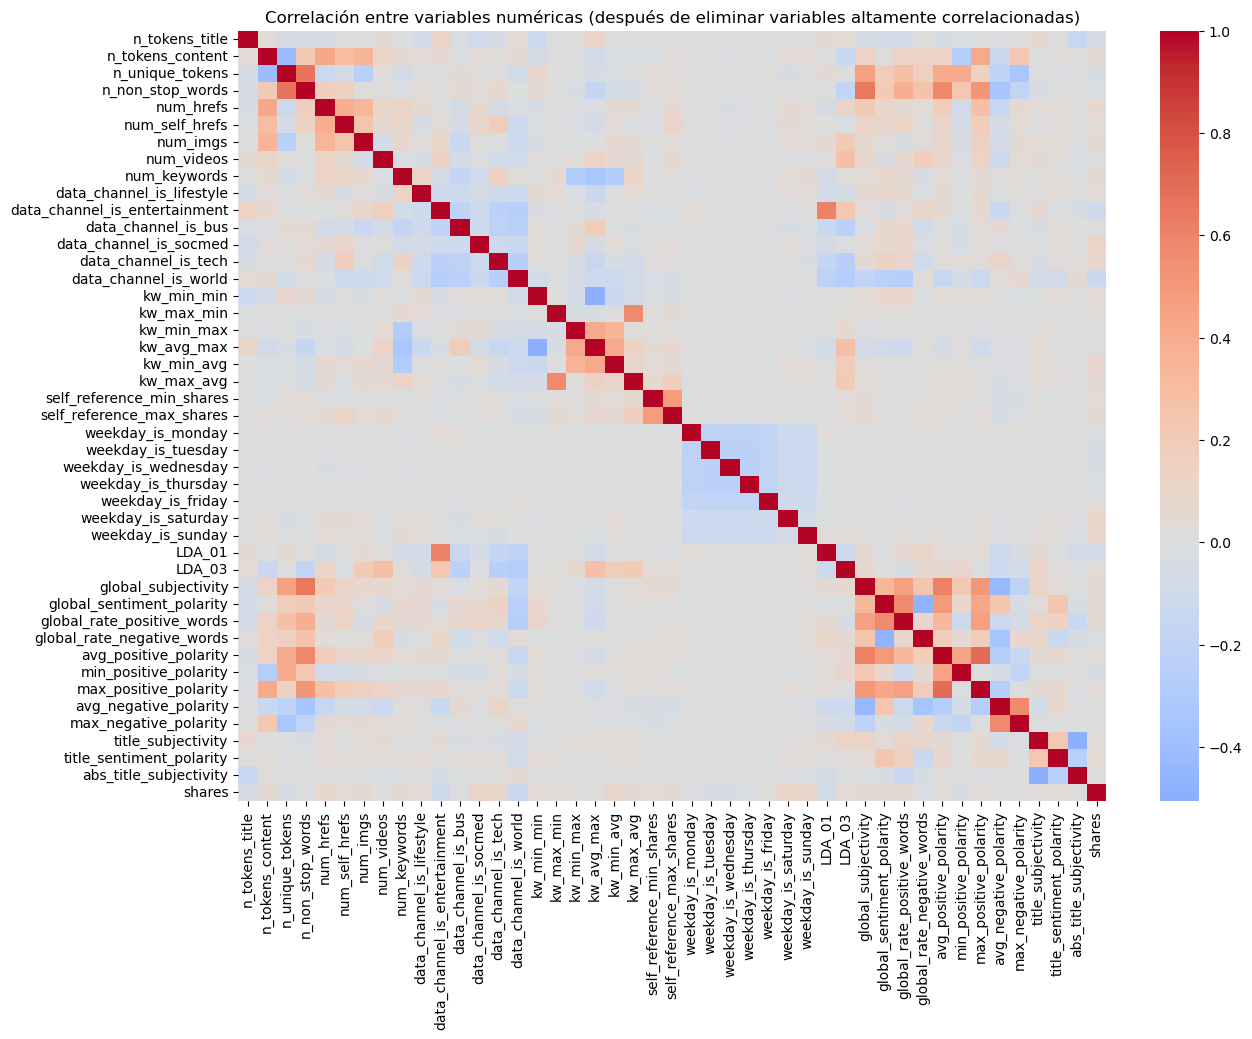

In [12]:
plt.figure(figsize=(14, 10))
sns.heatmap(df2_reducido.corr(), annot=False, cmap='coolwarm', center=0)
plt.title('Correlación entre variables numéricas (después de eliminar variables altamente correlacionadas)')
plt.show()

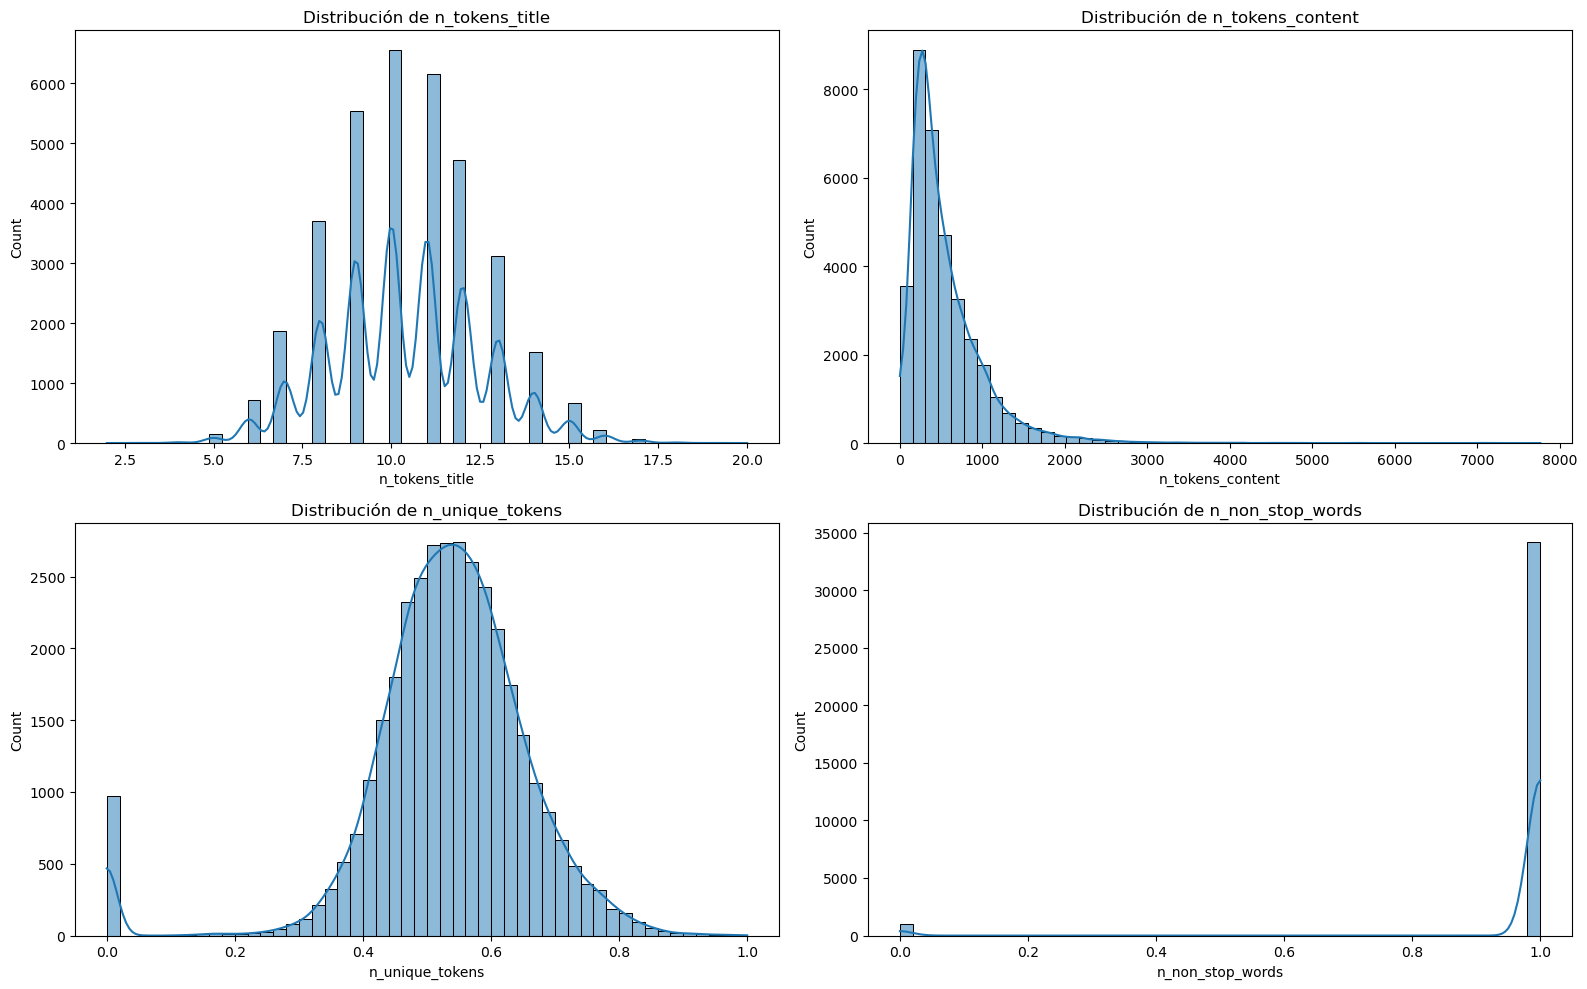

In [13]:
variables_elegidas = df2_reducido.columns[:4]

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 10))
for i, var in enumerate(variables_elegidas, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df2_reducido[var], kde=True, bins=50)
    plt.title(f'Distribución de {var}')
plt.tight_layout()
plt.show()

In [14]:
scaler = StandardScaler()
numericas_norm = scaler.fit_transform(df2_reducido)

df_norm = pd.DataFrame(numericas_norm, columns=df2_reducido.columns)

In [15]:
# Defino X (variables numéricas normalizadas) y y (variable objetivo)
X = df_norm.drop(columns=['shares']) if 'shares' in df_norm.columns else df_norm
y = df2_reducido['shares'] if 'shares' in df2_reducido.columns else None  # Cambiar si necesario

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
if y is not None:
    print(f"y_train shape: {y_train.shape}, y_test shape: {y_test.shape}")

Train shape: (23519, 44), Test shape: (11584, 44)
y_train shape: (23519,), y_test shape: (11584,)


In [44]:
param_grid = {
    'n_estimators': np.linspace(100, 300, 10, dtype=int),  # 10 valores entre 100 y 300
    'max_depth': np.linspace(2, 15, 10, dtype=int),       # 10 valores entre 2 y 15
    'max_features': ['sqrt', 'log2']
}

In [47]:
rf = RandomForestRegressor(random_state=42)

In [48]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,             # validación cruzada 5 folds
    scoring='neg_mean_squared_error',  # Métrica para regresión, cambiar si es clasificación
    n_jobs=-1,        # usar todos los cores
    verbose=2
)

In [49]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': array([ 2,  3,  4,  6,  7,  9, 10, 12, 13, 15]),
                         'max_features': ['sqrt', 'log2'],
                         'n_estimators': array([100, 122, 144, 166, 188, 211, 233, 255, 277, 300])},
             scoring='neg_mean_squared_error', verbose=2)

In [50]:
print("Mejores parámetros encontrados:", grid_search.best_params_)
print("Mejor score (neg MSE):", grid_search.best_score_)

Mejores parámetros encontrados: {'max_depth': 15, 'max_features': 'sqrt', 'n_estimators': 277}
Mejor score (neg MSE): -1069090.148040352


In [55]:
model = Sequential()
model.add(Dense(512, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.3))
model.add(Dense(384, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1))  # salida para regresión, sin activación

# Compilar modelo
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mse'])

# Entrenar
history = model.fit(X_train, y_train,
                    epochs=50,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=1)

# Evaluar en test
y_pred = model.predict(X_test).flatten()

# Métricas
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.4f}")
print(f"Test R^2: {r2:.4f}")

Epoch 1/50
294/294 [==============================] - 2s 5ms/step - loss: 1875866.7500 - mse: 1875866.7500 - val_loss: 1164443.3750 - val_mse: 1164443.3750
Epoch 2/50
294/294 [==============================] - 1s 3ms/step - loss: 1149848.3750 - mse: 1149848.3750 - val_loss: 1131574.3750 - val_mse: 1131574.3750
Epoch 3/50
294/294 [==============================] - 1s 3ms/step - loss: 1121767.7500 - mse: 1121767.7500 - val_loss: 1121642.5000 - val_mse: 1121642.5000
Epoch 4/50
294/294 [==============================] - 1s 3ms/step - loss: 1112420.5000 - mse: 1112420.5000 - val_loss: 1114422.2500 - val_mse: 1114422.2500
Epoch 5/50
294/294 [==============================] - 1s 4ms/step - loss: 1104971.6250 - mse: 1104971.6250 - val_loss: 1107286.1250 - val_mse: 1107286.1250
Epoch 6/50
294/294 [==============================] - 1s 4ms/step - loss: 1098335.8750 - mse: 1098335.8750 - val_loss: 1109121.8750 - val_mse: 1109121.8750
Epoch 7/50
294/294 [==============================] - 1s 4ms/ste

In [16]:
# Definimos el modelo base (regresión, si es clasificación cambia a XGBClassifier)
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

# Parámetros para GridSearch
param_grid = {
    'n_estimators': [100, 120, 150, 200, 300],
    'learning_rate': [0.008, 0.07, 0.009, 0.01, 0.02],
    'subsample': np.linspace(0.05, 1, 5),
    'scale_pos_weight': np.linspace(0.8, 0.9, 2)
}

# Configuramos GridSearch con 5 folds
grid_search = GridSearchCV(estimator=xgb,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_mean_squared_error',  # para regresión
                           verbose=1,
                           n_jobs=-1)

# Entrenamos la búsqueda
grid_search.fit(X_train, y_train)

# Resultados
print(f"Mejores parámetros: {grid_search.best_params_}")
print(f"Mejor score (neg MSE): {grid_search.best_score_}")

# Evaluamos el mejor modelo en test
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE en test: {mse:.4f}")
print(f"R^2 en test: {r2:.4f}")

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Mejores parámetros: {'learning_rate': 0.02, 'n_estimators': 300, 'scale_pos_weight': 0.8, 'subsample': 0.525}
Mejor score (neg MSE): -1056801.875
MSE en test: 1031854.6875
R^2 en test: 0.1455


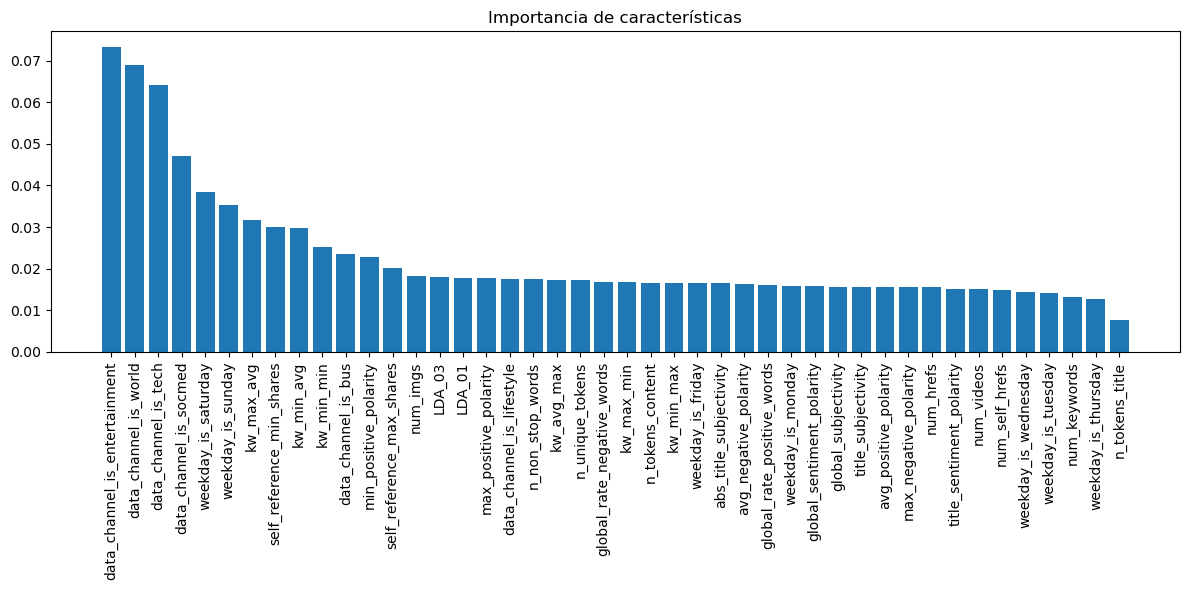

In [17]:
importances = best_model.feature_importances_

# Ordenamos las características de mayor a menor importancia
indices = np.argsort(importances)[::-1]

# Si tienes nombres de variables numéricas, por ejemplo:
feature_names = X_train.columns if hasattr(X_train, 'columns') else [f'feature_{i}' for i in range(X_train.shape[1])]

plt.figure(figsize=(12, 6))
plt.title("Importancia de características")
plt.bar(range(len(importances)), importances[indices], align="center")
plt.xticks(range(len(importances)), [feature_names[i] for i in indices], rotation=90)
plt.tight_layout()
plt.show()

In [34]:
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

In [38]:
models = [
    LinearRegression(),
    DecisionTreeRegressor(max_depth=5),
    SVR(kernel='rbf'),
]

trained_models, yhat_test, yhat_out, idx_oob = ubagging.bagging_het(
    pd.DataFrame(X_train, columns=X.columns),
    y_train,
    200,
    models,
    pd.DataFrame(X_test, columns=X.columns)
)

# Promedio de las predicciones
y_pred_ensemble = yhat_test.mean(axis=1)

# Evaluación
mse = mean_squared_error(y_test, y_pred_ensemble)
r2 = r2_score(y_test, y_pred_ensemble)
mae = mean_absolute_error(y_test, y_pred_ensemble)

print(f'MSE: {mse:.4f}, R2: {r2:.4f}, MAE: {mae:.4f}')

KeyboardInterrupt: 

Lo tuve que dejar sin correr por que lleva 41 minutos y todavia no me devolvio nada, estoy usando el kernel con la gpu